In [2]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as mp
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

df = pd.read_csv("IPL.csv")
df.head()

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,second_ings_score,second_ings_wkts,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure
0,1,"March 26,2022","Wankhede Stadium, Mumbai",Chennai,Kolkata,Group,Kolkata,Field,131,5,133,4,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20
1,2,"March 27,2022","Brabourne Stadium, Mumbai",Delhi,Mumbai,Group,Delhi,Field,177,5,179,6,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18
2,3,"March 27,2022","Dr DY Patil Sports Academy, Mumbai",Banglore,Punjab,Group,Punjab,Field,205,2,208,5,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59
3,4,"March 28,2022","Wankhede Stadium, Mumbai",Gujarat,Lucknow,Group,Gujarat,Field,158,6,161,5,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25
4,5,"March 29,2022","Maharashtra Cricket Association Stadium,Pune",Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,149,7,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 74 entries, 0 to 73
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   match_id             74 non-null     int64
 1   date                 74 non-null     str  
 2   venue                74 non-null     str  
 3   team1                74 non-null     str  
 4   team2                74 non-null     str  
 5   stage                74 non-null     str  
 6   toss_winner          74 non-null     str  
 7   toss_decision        74 non-null     str  
 8   first_ings_score     74 non-null     int64
 9   first_ings_wkts      74 non-null     int64
 10  second_ings_score    74 non-null     int64
 11  second_ings_wkts     74 non-null     int64
 12  match_winner         74 non-null     str  
 13  won_by               74 non-null     str  
 14  margin               74 non-null     int64
 15  player_of_the_match  74 non-null     str  
 16  top_scorer           74 non-null     st

In [4]:
df.shape

(74, 20)

In [5]:
df.isnull().sum()

match_id               0
date                   0
venue                  0
team1                  0
team2                  0
stage                  0
toss_winner            0
toss_decision          0
first_ings_score       0
first_ings_wkts        0
second_ings_score      0
second_ings_wkts       0
match_winner           0
won_by                 0
margin                 0
player_of_the_match    0
top_scorer             0
highscore              0
best_bowling           0
best_bowling_figure    0
dtype: int64

In [6]:
df.duplicated()

0     False
1     False
2     False
3     False
4     False
      ...  
69    False
70    False
71    False
72    False
73    False
Length: 74, dtype: bool

In [7]:
def extract_city(txt):
    city=txt.split(",")[1]
    return city
df['city']=df['venue'].apply(extract_city)

In [8]:
def extract_vnue(txt):
    vne=txt.split(",")[0]
    return vne
df['venue']=df['venue'].apply(extract_vnue)
df.head()

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,...,second_ings_wkts,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure,city
0,1,"March 26,2022",Wankhede Stadium,Chennai,Kolkata,Group,Kolkata,Field,131,5,...,4,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20,Mumbai
1,2,"March 27,2022",Brabourne Stadium,Delhi,Mumbai,Group,Delhi,Field,177,5,...,6,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18,Mumbai
2,3,"March 27,2022",Dr DY Patil Sports Academy,Banglore,Punjab,Group,Punjab,Field,205,2,...,5,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59,Mumbai
3,4,"March 28,2022",Wankhede Stadium,Gujarat,Lucknow,Group,Gujarat,Field,158,6,...,5,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25,Mumbai
4,5,"March 29,2022",Maharashtra Cricket Association Stadium,Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,...,7,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22,Pune


In [9]:
def extract_tossmatch_win(bf):
    ans=""
    if bf['toss_winner']==bf['match_winner']:
        return True
    else:
        return False
df['Toss_Match_Win']=df[['toss_winner','match_winner']].apply(extract_tossmatch_win , axis=1)
df.head()

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,...,match_winner,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure,city,Toss_Match_Win
0,1,"March 26,2022",Wankhede Stadium,Chennai,Kolkata,Group,Kolkata,Field,131,5,...,Kolkata,Wickets,6,Umesh Yadav,MS Dhoni,50,Dwayne Bravo,3--20,Mumbai,True
1,2,"March 27,2022",Brabourne Stadium,Delhi,Mumbai,Group,Delhi,Field,177,5,...,Delhi,Wickets,4,Kuldeep Yadav,Ishan Kishan,81,Kuldeep Yadav,3--18,Mumbai,True
2,3,"March 27,2022",Dr DY Patil Sports Academy,Banglore,Punjab,Group,Punjab,Field,205,2,...,Punjab,Wickets,5,Odean Smith,Faf du Plessis,88,Mohammed Siraj,2--59,Mumbai,True
3,4,"March 28,2022",Wankhede Stadium,Gujarat,Lucknow,Group,Gujarat,Field,158,6,...,Gujarat,Wickets,5,Mohammed Shami,Deepak Hooda,55,Mohammed Shami,3--25,Mumbai,True
4,5,"March 29,2022",Maharashtra Cricket Association Stadium,Hyderabad,Rajasthan,Group,Hyderabad,Field,210,6,...,Rajasthan,Runs,61,Sanju Samson,Aiden Markram,57,Yuzvendra Chahal,3--22,Pune,False


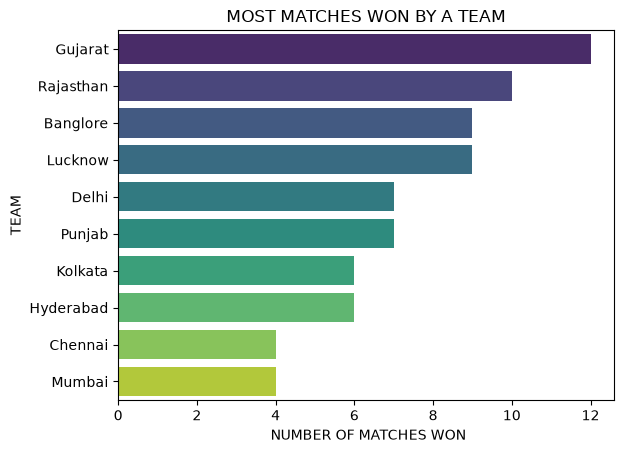

In [10]:
# WHICH TEAM WINS THE MOST MATCHES 

match_wins = df['match_winner'].value_counts()
sns.barplot( y = match_wins.index , x=match_wins.values , palette='viridis')
mp.title('MOST MATCHES WON BY A TEAM')
mp.xlabel(' NUMBER OF MATCHES WON')
mp.ylabel('TEAM')
mp.show()

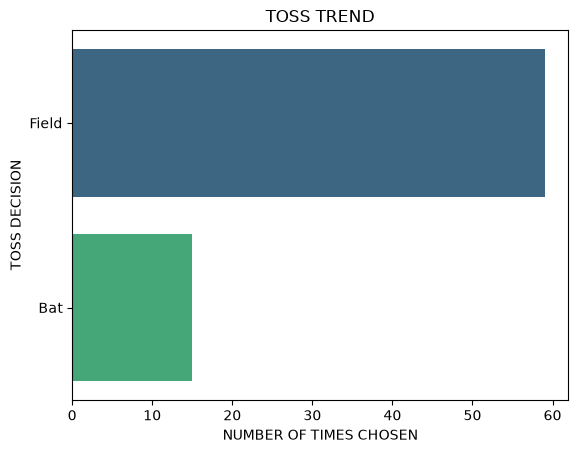

In [11]:


toss_trend = df['toss_decision'].value_counts()
sns.barplot( x=toss_trend.values , y=toss_trend.index ,palette='viridis')
mp.title('TOSS TREND')
mp.xlabel('NUMBER OF TIMES CHOSEN')
mp.ylabel('TOSS DECISION')
mp.show()

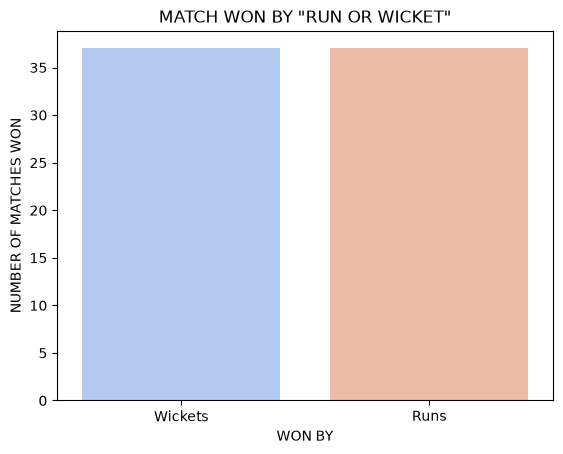

In [12]:
#HOW MATCH WAS WON?? BY RUNS OR BY WICKETS??

sns.countplot(x=df['won_by'] , palette='coolwarm')
mp.title('MATCH WON BY "RUN OR WICKET"')
mp.xlabel('WON BY')
mp.ylabel('NUMBER OF MATCHES WON')
mp.show()

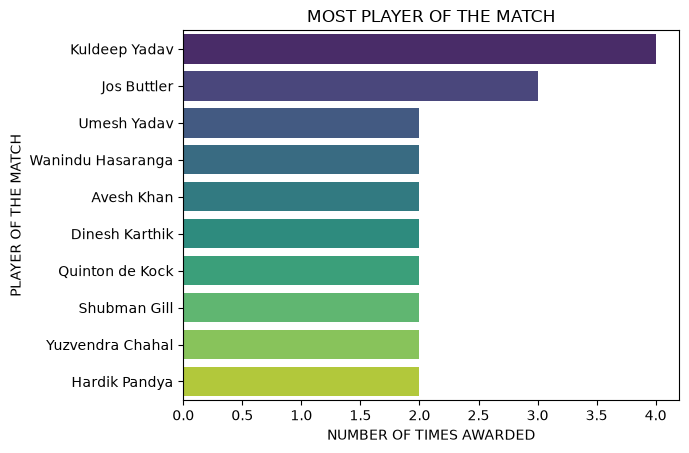

In [13]:
# MOST PLLAYER OF THE MATCH AWARD 

count = df['player_of_the_match'].value_counts().head(10)
sns.barplot( x=count.values , y=count.index , palette='viridis')
mp.title('MOST PLAYER OF THE MATCH')
mp.xlabel('NUMBER OF TIMES AWARDED')
mp.ylabel('PLAYER OF THE MATCH')
mp.show()

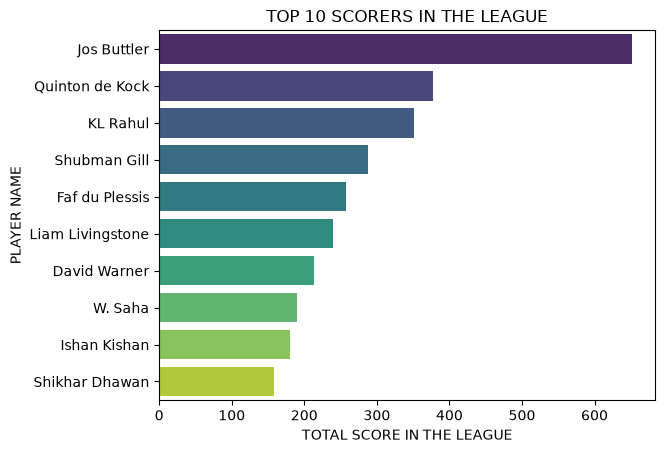

In [14]:
#top 10 scorer in the league

high = df.groupby('top_scorer')['highscore'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=high.values, y=high.index, palette='viridis')
mp.title('TOP 10 SCORERS IN THE LEAGUE')
mp.xlabel('TOTAL SCORE IN THE LEAGUE')
mp.ylabel('PLAYER NAME')
mp.show()

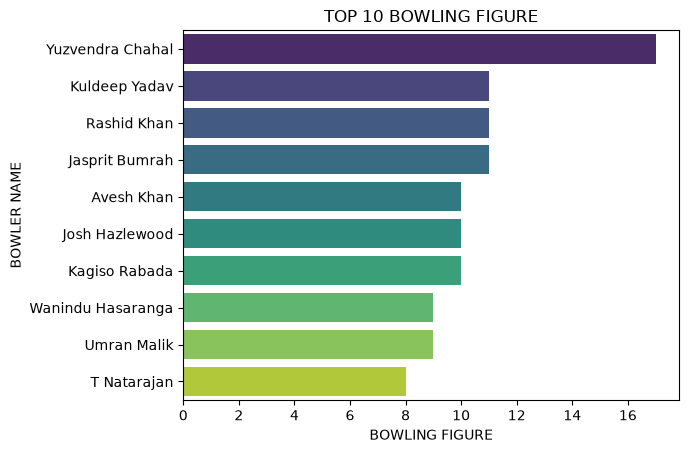

In [15]:
df['wickets']=df['best_bowling_figure'].apply(lambda x:x.split("--")[0]).astype(int)
bhigh = df.groupby('best_bowling')['wickets'].sum().sort_values(ascending=False).head(10)
sns.barplot(x=bhigh.values, y=bhigh.index , palette='viridis')
mp.title('TOP 10 BOWLING FIGURE')
mp.xlabel('BOWLING FIGURE')
mp.ylabel('BOWLER NAME')
mp.show()

<function matplotlib.pyplot.show(close=None, block=None)>

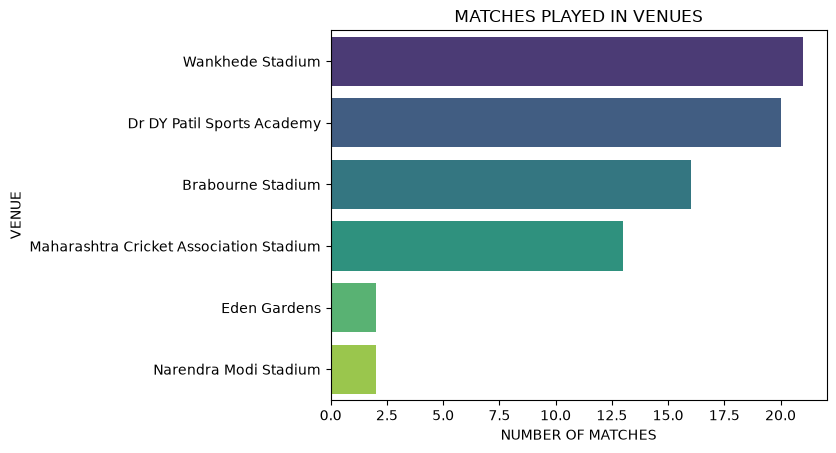

In [16]:
#number matches played in each stadium

sns.barplot(x=df['venue'].value_counts().values, y=df['venue'].value_counts().index, palette='viridis')
mp.title('MATCHES PLAYED IN VENUES')
mp.xlabel('NUMBER OF MATCHES')
mp.ylabel('VENUE')
mp.show

<function matplotlib.pyplot.show(close=None, block=None)>

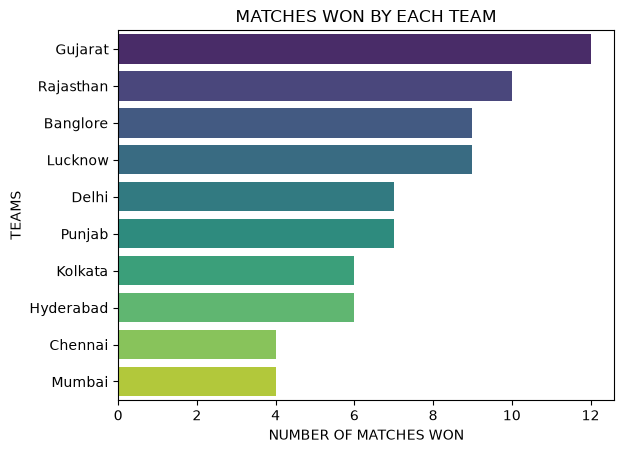

In [17]:
# number of matches won by each team

sns.barplot(x=df['match_winner'].value_counts().values, y=df['match_winner'].value_counts().index, palette='viridis')
mp.title('MATCHES WON BY EACH TEAM')
mp.xlabel('NUMBER OF MATCHES WON')
mp.ylabel('TEAMS')
mp.show

In [18]:
#WHO WON THE HIGHEST MARGIN BY RUNS 

df[df['won_by']=="Runs"].sort_values(by ='margin', ascending =False).head(1)

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,...,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure,city,Toss_Match_Win,wickets
54,55,"May 8,2022",Dr DY Patil Sports Academy,Chennai,Delhi,Group,Delhi,Field,208,6,...,Runs,91,Devon Conway,Devon Conway,87,Moeen Ali,3--13,Mumbai,False,3


In [19]:
df[df['highscore']==df['highscore'].max()]

,match_id,date,venue,team1,team2,stage,toss_winner,toss_decision,first_ings_score,first_ings_wkts,...,won_by,margin,player_of_the_match,top_scorer,highscore,best_bowling,best_bowling_figure,city,Toss_Match_Win,wickets
65,66,"May 18,2022",Dr DY Patil Sports Academy,Kolkata,Lucknow,Group,Lucknow,Bat,210,0,...,Runs,2,Quinton de Kock,Quinton de Kock,140,Mohsin Khan,3--20,Mumbai,True,3


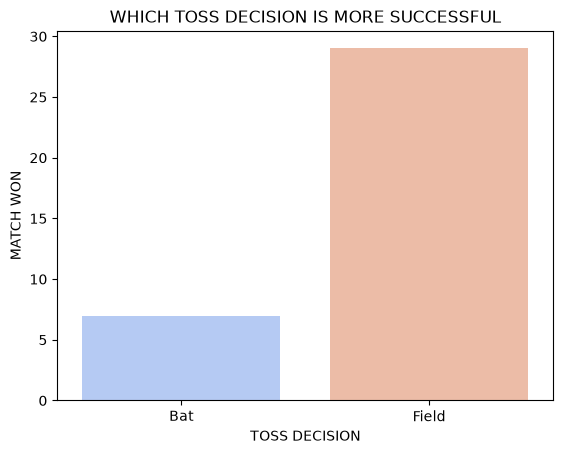

as we can see in toss_decision
Bat       7
Field    29
Name: Toss_Match_Win, dtype: int64 , so according to it 
Fielding is more succesful


In [28]:
#which toss decision is more successful "batting or fielding" :-

dt = df.groupby('toss_decision')['Toss_Match_Win'].sum()
sns.barplot(x=dt.index,y=dt.values,palette='coolwarm')
mp.title('WHICH TOSS DECISION IS MORE SUCCESSFUL')
mp.xlabel('TOSS DECISION')
mp.ylabel('MATCH WON')
mp.show()
print(f"as we can see in {dt} , so according to it \n{dt.index[1]}ing is more succesful")

In [31]:
df.head()
df['team1'].count_values().sum()

AttributeError: 'Series' object has no attribute 'count_values'